# Notebook 24 — MISO overhead AC transmission capacity–cost exploration

Build an independent engineering reference for `ELC_TRANS` using MISO's **clean
May 1, 2024 MTEP24 Transmission Cost Estimation Guide**. The user-supplied redline
contains deleted/replacement values; it is not the numerical source for this notebook.

Like notebook 23, this notebook audits coverage, defines cost boundaries, produces
discrete design options, explores scale relationships and saves review outputs.
Unlike AESO, MISO supplies indicative capacities matched to its own cost assumptions.
These are **engineered state/design scenarios**, not observed independent projects.
No AESO ratings, production cost layers, registry or model database is modified.

Run top to bottom in the repository `.venv`. Inputs are pinned in
`data_files/models/cost_models/transmission/miso/`; no network access is needed.
Outputs go to `data_files/processed/transmission/miso/notebook24/`.

References: [clean MTEP24 guide](https://cdn.misoenergy.org/20240501%20PSC%20Item%2004%20MISO%20Transmission%20Cost%20Estimation%20Guide%20for%20MTEP24632680.pdf),
[official update presentation](https://cdn.misoenergy.org/20240131%20PSC%20Item%2005%20Transmission%20Cost%20Estimation%20Guide%20for%20MTEP24631525.pdf).
See the input folder's README and source provenance for table/page locators.

## 1. Load source provenance and explicit scenarios

The guide's printed p. 1 says both “2023 U.S. dollars” and that costs were escalated
from 2023 to 2024. We use **2024 as a working interpretation**, supported by MISO's
update presentation, and retain a 2023 price-year sensitivity. We do not escalate
the source table a second time. Both interpretations use the same quoted values.

The source guide is dated 2024; this is not a claim that it is MISO's latest edition.
Dollar-year interpretation, source publication date, capacity basis and scenario
selection are separate metadata.

In [1]:
from pathlib import Path
import hashlib
import json
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src/geocanoe').is_dir())
INPUTS = ROOT / 'data_files/models/cost_models/transmission/miso'
OUT = ROOT / 'data_files/processed/transmission/miso/notebook24'
OUT.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(ROOT / 'src'))
from geocanoe.costs.economics import conversion_basis

CONFIG = json.loads((INPUTS / 'analysis_assumptions.json').read_text(encoding='utf8'))
PROVENANCE = json.loads((INPUTS / 'source_provenance.json').read_text(encoding='utf8'))
def sha256(path):
    return hashlib.sha256(path.read_bytes()).hexdigest()

assert sha256(INPUTS / PROVENANCE['pdf_file']) == PROVENANCE['pdf_sha256']
for name, digest in PROVENANCE['files'].items():
    assert sha256(INPUTS / name) == digest, f'Review changed source table: {name}'
assert CONFIG['use_for_production'] is False
assert CONFIG['source_price_year'] in CONFIG['price_year_sensitivity']
assert 0 < CONFIG['power_factor_scenario'] <= 1
assert CONFIG['distance_basis'] == 'route_km_interpretation'
assert CONFIG['contingency_fraction'] == .30 and CONFIG['afudc_fraction'] == .075
display(pd.Series(CONFIG, name='Exploratory assumptions'))
lines = pd.read_csv(INPUTS / 'ac_line_costs.csv')
ratings = pd.read_csv(INPUTS / 'ac_design_ratings.csv')
states = pd.read_csv(INPUTS / 'state_land_terrain.csv')
stations = pd.read_csv(INPUTS / 'ac_station_costs.csv')
terrain_adders = pd.read_csv(INPUTS / 'terrain_adders.csv')

source_price_year                                                        2024
price_year_sensitivity                                           [2023, 2024]
minimum_voltage_kv                                                        115
power_factor_scenario                                                     1.0
contingency_fraction                                                      0.3
afudc_fraction                                                          0.075
distance_basis                                        route_km_interpretation
reference_state                                                     Minnesota
reference_voltage_kv                                                      230
terminal_bus_arrangement                                                 ring
route_lengths_km                                      [10, 50, 100, 250, 500]
project_scope               new AC line plus one or two ring-bus line posi...
capacity_basis              summed indicative circuit MVA times 

## 2. Audit coverage and distinguish scenarios from independent observations

Tables 4.1-1/2 provide 15 states × (8 single-circuit + 6 double-circuit voltages).
Default selection is at least 115 kV. 69 kV remains in the source tables but is outside
the initial high-voltage fit. No double-circuit 500/765 kV costs are supplied: they
remain absent rather than extrapolated.

State variation represents MISO's assumed land/terrain and other cost differences,
not 15 independent project samples per design. Report the number of unique designs
alongside the scenario count. Do not random-split state/design rows to claim accuracy
on new projects or Canada.

In [2]:
assert len(lines) == 210 and len(ratings) == 8 and len(states) == 15 and len(stations) == 96
assert not lines.duplicated(['state', 'voltage_kv', 'circuits']).any()
assert not ratings.duplicated('voltage_kv').any()
assert not stations.duplicated(['scope', 'positions', 'bus_arrangement', 'voltage_kv']).any()
assert lines.cost_usd_per_mile.gt(0).all()
assert stations.cost_usd_per_station.gt(0).all()
assert lines[['state','voltage_kv','circuits','cost_usd_per_mile']].notna().all().all()
assert set(lines.state) == set(states.state)
assert np.allclose(states[['pasture_fraction','cropland_fraction','urban_fraction']].sum(axis=1), 1)
assert np.allclose(states[['level_fraction','forest_fraction','wetland_fraction']].sum(axis=1), 1)
selected = lines.loc[lines.voltage_kv.ge(CONFIG['minimum_voltage_kv'])].copy()
assert not selected.empty
display(pd.Series({'source_scenarios': len(lines), 'selected_scenarios': len(selected),
                   'states': selected.state.nunique(),
                   'unique_selected_designs': len(selected[['voltage_kv','circuits']].drop_duplicates()),
                   'actual_project_observations': 0}, name='Coverage'))
display(pd.crosstab(selected.voltage_kv, selected.circuits).rename_axis(columns='Circuits'))
display(ratings)

source_scenarios               210
selected_scenarios             180
states                          15
unique_selected_designs         12
actual_project_observations      0
Name: Coverage, dtype: int64
Circuits     1   2
voltage_kv        
115         15  15
138         15  15
161         15  15
230         15  15
345         15  15
500         15   0
765         15   0
   voltage_kv  ...                                       rating_basis
0          69  ...  MISO indicative per-circuit rating; weather/te...
1         115  ...  MISO indicative per-circuit rating; weather/te...
2         138  ...  MISO indicative per-circuit rating; weather/te...
3         161  ...  MISO indicative per-circuit rating; weather/te...
4         230  ...  MISO indicative per-circuit rating; weather/te...
5         345  ...  MISO indicative per-circuit rating; weather/te...
6         500  ...  MISO indicative per-circuit rating; weather/te...
7         765  ...  MISO indicative per-circuit rating; weather/t

## 3. Match MISO's own per-circuit ratings and normalize line costs

Table 3.1-5 ratings are **per circuit**. Its amp rating already reflects the phase
bundle, so do not multiply by conductor quantity again. The rounded source MVA rating
is used directly; `sqrt(3) × kV × circuit_A / 1000` is a rounding check.

For a double-circuit design, the capacity scenario sums two circuit ratings. This is
neither N-1 firm capacity nor a network transfer limit. MVA becomes MW only through
the explicit power-factor scenario. Rating weather/temperature is not specified in
the indicative table, so these ratings must not silently populate AESO ACSR designs.

Quoted single/double-circuit $/mile is interpreted as **route-mile** for the respective
whole line. Convert by dividing by 1.609344; do not multiply double-circuit cost by two.
The quote includes 30% contingency and AFUDC of 7.5% on project cost plus contingency.
The implied project-cost subtotal is therefore quote / (1.30 × 1.075). This subtotal
still need not match AESO's component coverage or the model's overnight CAPEX boundary.

In [3]:
MILES_TO_KM = 1.609344
ADDER_FACTOR = (1 + CONFIG['contingency_fraction']) * (1 + CONFIG['afudc_fraction'])
basis = conversion_basis('USD', CONFIG['source_price_year'])
TARGET_CURRENCY = basis['target_currency']
data = selected.merge(ratings, on='voltage_kv', how='left', validate='many_to_one', suffixes=('_cost','_rating'))
assert data.capacity_mva_per_circuit.notna().all()
calculated_mva = np.sqrt(3) * ratings.voltage_kv * ratings.circuit_current_a / 1000
assert np.allclose(calculated_mva, ratings.capacity_mva_per_circuit, rtol=.005)
data['capacity_mva'] = data.capacity_mva_per_circuit * data.circuits
data['capacity_mw_scenario'] = data.capacity_mva * CONFIG['power_factor_scenario']
data['quoted_usd_per_route_km'] = data.cost_usd_per_mile / MILES_TO_KM
data['quoted_cad_per_route_km'] = data.quoted_usd_per_route_km * basis['multiplier']
data['project_subtotal_cad_per_route_km'] = data.quoted_cad_per_route_km / ADDER_FACTOR
data['quoted_cad_per_mw_km'] = data.quoted_cad_per_route_km / data.capacity_mw_scenario
data['project_subtotal_cad_per_mw_km'] = data.project_subtotal_cad_per_route_km / data.capacity_mw_scenario
data['target_currency'] = TARGET_CURRENCY
assert np.allclose(data.project_subtotal_cad_per_route_km * ADDER_FACTOR, data.quoted_cad_per_route_km)
display(data[['state','voltage_kv','circuits','capacity_mva','capacity_mw_scenario',
              'quoted_cad_per_route_km','project_subtotal_cad_per_route_km','quoted_cad_per_mw_km']].head(14))
print('Price-year interpretation:', CONFIG['source_price_year'], '| target:', TARGET_CURRENCY,
      '| conversion multiplier:', basis['multiplier'], '| embedded-adder factor:', ADDER_FACTOR)

       state  ...  quoted_cad_per_mw_km
0   Arkansas  ...           3621.682704
1   Arkansas  ...           3183.365241
2   Arkansas  ...           2862.952609
3   Arkansas  ...           2099.955092
4   Arkansas  ...           1224.849517
5   Arkansas  ...           1062.101998
6   Arkansas  ...            520.630376
7   Illinois  ...           3812.297583
8   Illinois  ...           3183.365241
9   Illinois  ...           2862.952609
10  Illinois  ...           2099.955092
11  Illinois  ...           1259.845217
12  Illinois  ...           1086.240680
13  Illinois  ...            530.096382

[14 rows x 8 columns]
Price-year interpretation: 2024 | target: CAD2020 | conversion multiplier: 1.009256560821485 | embedded-adder factor: 1.3975


## 4. Discrete design options and descriptive state ranges

The equal-state median is a transparent reference, not a geography-weighted Canadian
estimate. State minima/maxima and interquartile ranges are descriptive engineering
scenario ranges, not prediction/confidence intervals. Prefer discrete options if a
smooth curve conceals changes in voltage, conductors or circuit structure.

    voltage_kv  ...  target_currency
0          115  ...          CAD2020
1          115  ...          CAD2020
2          138  ...          CAD2020
3          138  ...          CAD2020
4          161  ...          CAD2020
5          161  ...          CAD2020
6          230  ...          CAD2020
7          230  ...          CAD2020
8          345  ...          CAD2020
9          345  ...          CAD2020
10         500  ...          CAD2020
11         765  ...          CAD2020

[12 rows x 13 columns]


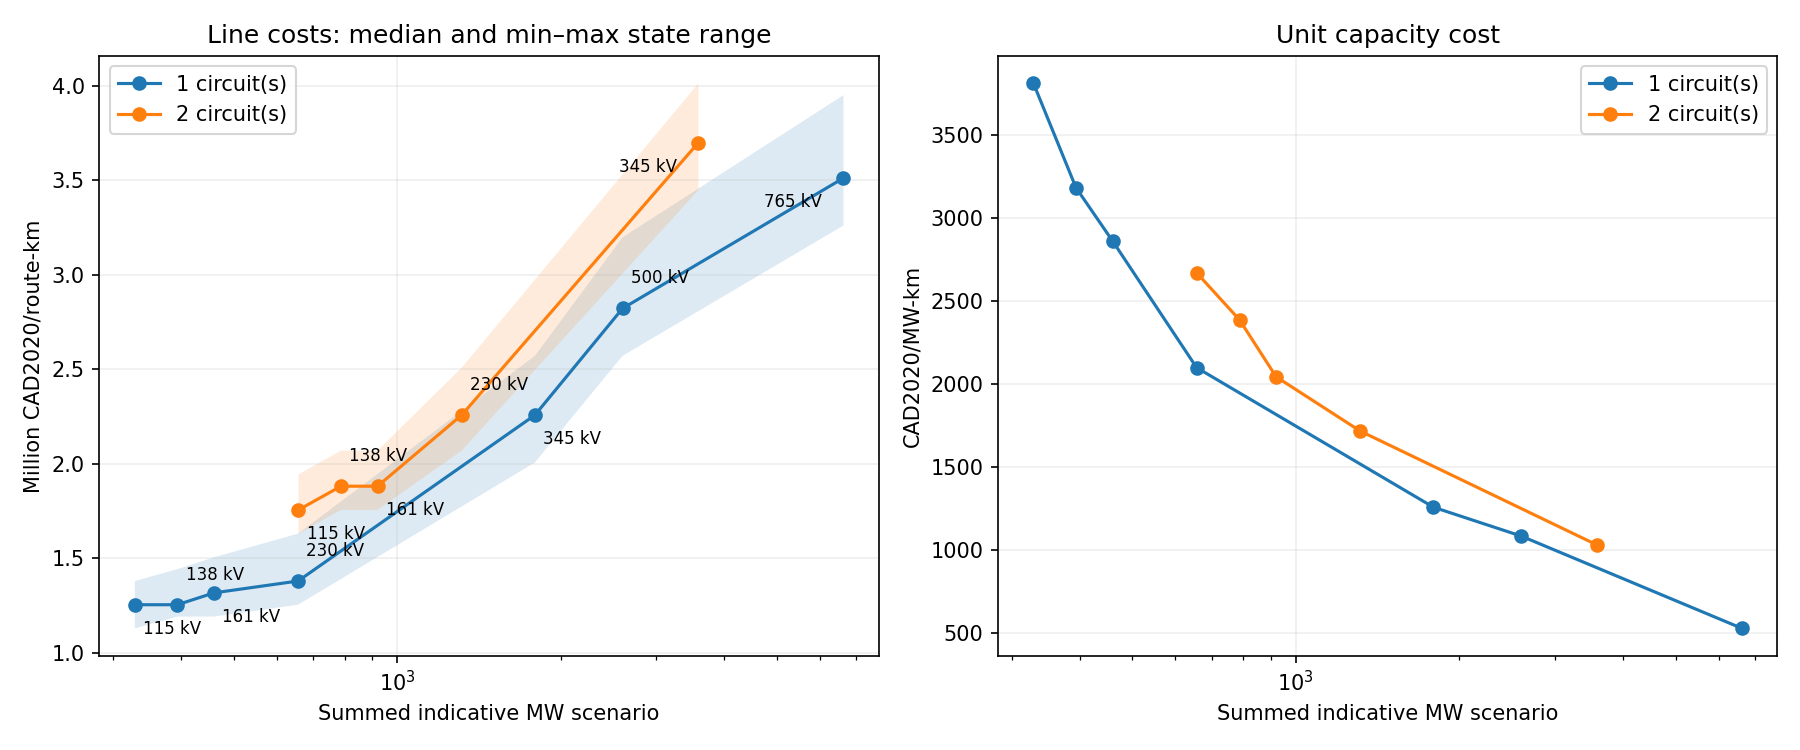

In [4]:
options = data.groupby(['voltage_kv','circuits','capacity_mva','capacity_mw_scenario']).agg(
    n_state_scenarios=('state','nunique'),
    quoted_median_cad_per_route_km=('quoted_cad_per_route_km','median'),
    quoted_min_cad_per_route_km=('quoted_cad_per_route_km','min'),
    quoted_max_cad_per_route_km=('quoted_cad_per_route_km','max'),
    quoted_p25_cad_per_route_km=('quoted_cad_per_route_km',lambda s:s.quantile(.25)),
    quoted_p75_cad_per_route_km=('quoted_cad_per_route_km',lambda s:s.quantile(.75)),
).reset_index()
options['median_cad_per_mw_km'] = options.quoted_median_cad_per_route_km / options.capacity_mw_scenario
options['project_subtotal_median_cad_per_route_km'] = options.quoted_median_cad_per_route_km / ADDER_FACTOR
options['target_currency'] = TARGET_CURRENCY
display(options)
fig, axes = plt.subplots(1, 2, figsize=(12,5))
for circuits, g in options.groupby('circuits'):
    g = g.sort_values('capacity_mw_scenario')
    x = g.capacity_mw_scenario.to_numpy()
    y = g.quoted_median_cad_per_route_km.to_numpy()/1e6
    axes[0].plot(x,y,'o-',label=f'{circuits} circuit(s)')
    axes[0].fill_between(x,g.quoted_min_cad_per_route_km.to_numpy()/1e6,
                         g.quoted_max_cad_per_route_km.to_numpy()/1e6,alpha=.15)
    axes[1].plot(x,g.median_cad_per_mw_km,'o-',label=f'{circuits} circuit(s)')
    for j, (_, row) in enumerate(g.iterrows()):
        axes[0].annotate(f'{int(row.voltage_kv)} kV',(row.capacity_mw_scenario,row.quoted_median_cad_per_route_km/1e6),
                         xytext=((-38 if j==len(g)-1 else 4), (12 if j%2 else -14)),textcoords='offset points',fontsize=8)
axes[0].set(xlabel='Summed indicative MW scenario',ylabel=f'Million {TARGET_CURRENCY}/route-km',
            title='Line costs: median and min–max state range')
axes[1].set(xlabel='Summed indicative MW scenario',ylabel=f'{TARGET_CURRENCY}/MW-km',title='Unit capacity cost')
for ax in axes:
    ax.set_xscale('log'); ax.legend(); ax.grid(alpha=.2)
fig.tight_layout()
fig.savefig(OUT/'design_costs.png',dpi=150)
plt.show()

## 5. Circuit-sharing economies at matched voltage and state

Compare double-circuit costs with two separate single-circuit lines at the same voltage
and state. Both have the same **summed nominal capacity** in this simplified scenario,
but are not equivalent for corridor independence, common-mode outages, reliability,
terminal topology or network capability. The ratio describes MISO's tabulated design
costs, not a measured causal construction saving.

              median       min       max
voltage_kv                              
115         0.275000  0.250000  0.318182
138         0.275000  0.250000  0.304348
161         0.285714  0.236842  0.312500
230         0.195652  0.150000  0.230769
345         0.171429  0.140625  0.219512


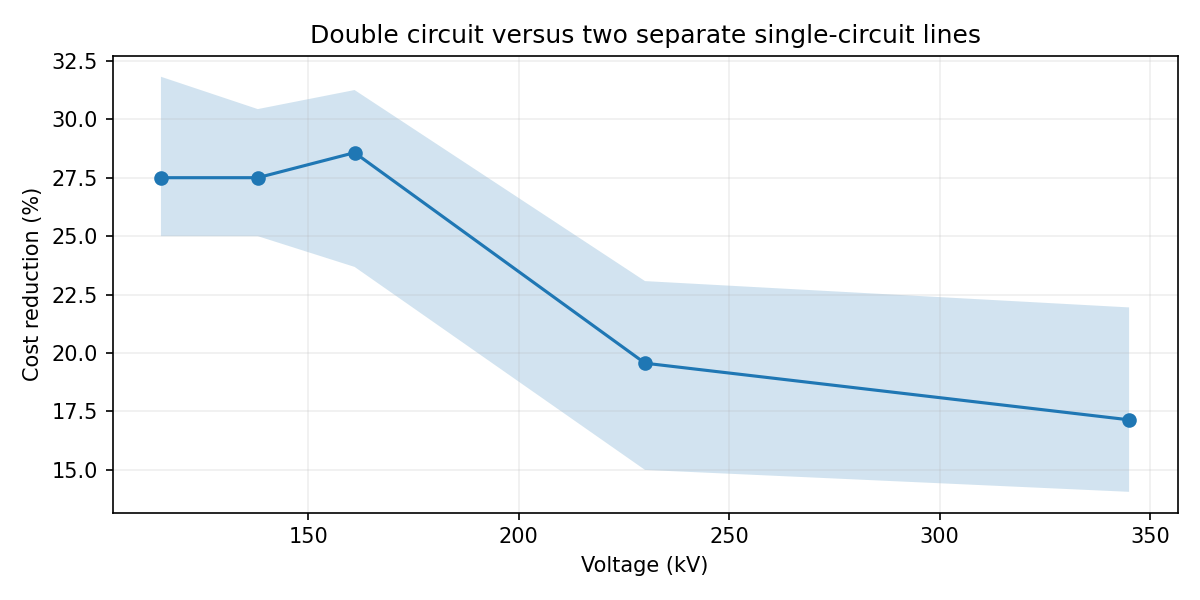

In [5]:
matched = data.pivot(index=['state','voltage_kv'],columns='circuits',values='quoted_cad_per_route_km').dropna()
matched['double_vs_two_single_cost_ratio'] = matched[2] / (2*matched[1])
matched['nominal_cost_reduction_fraction'] = 1-matched.double_vs_two_single_cost_ratio
circuit_summary = matched.groupby('voltage_kv').nominal_cost_reduction_fraction.agg(['median','min','max'])
display(circuit_summary)
fig, ax = plt.subplots(figsize=(8,4))
ax.plot(circuit_summary.index,circuit_summary['median']*100,'o-')
ax.fill_between(circuit_summary.index,circuit_summary['min']*100,circuit_summary['max']*100,alpha=.2)
ax.set(xlabel='Voltage (kV)',ylabel='Cost reduction (%)',title='Double circuit versus two separate single-circuit lines')
ax.grid(alpha=.2)
fig.tight_layout(); fig.savefig(OUT/'circuit_sharing.png',dpi=150); plt.show()

## 6. Power-law versus affine fits; leave one whole design out

Fit **equal-state median design costs**, separately for single/double circuits:
`quoted_cost_per_km = a × capacity_MW**b`. A fitted `0 < b < 1` describes declining
$/MW-km over the included designs. Voltage and capacity co-vary, so this is a descriptive
design-family relationship, not an independently identified causal scale exponent.

Compare power, affine (`a + bP`) and median-cost baselines. Leave out one whole voltage
design, not a random state row. Endpoint holdouts require extrapolation and are flagged;
interior holdouts test interpolation. These diagnostics reconstruct an engineering table,
not real-project or Canadian predictive accuracy. Do not interpret state rows as
independent replication or construct statistical confidence intervals from them.

Published line costs are rounded to .1 million/mile; fitted coefficients should not be interpreted as more precise than those inputs.

   circuits  ...                                   cost_scope
0         1  ...  quoted line including contingency and AFUDC
1         1  ...  quoted line including contingency and AFUDC
2         2  ...  quoted line including contingency and AFUDC
3         2  ...  quoted line including contingency and AFUDC

[4 rows x 9 columns]
                               n_holdouts  ...  invalid_predictions
circuits form   extrapolation              ...                     
1        affine False                   5  ...                    0
                True                    2  ...                    0
         power  False                   5  ...                    0
                True                    2  ...                    0
2        affine False                   3  ...                    0
                True                    2  ...                    0
         power  False                   3  ...                    0
                True                    2  ...          

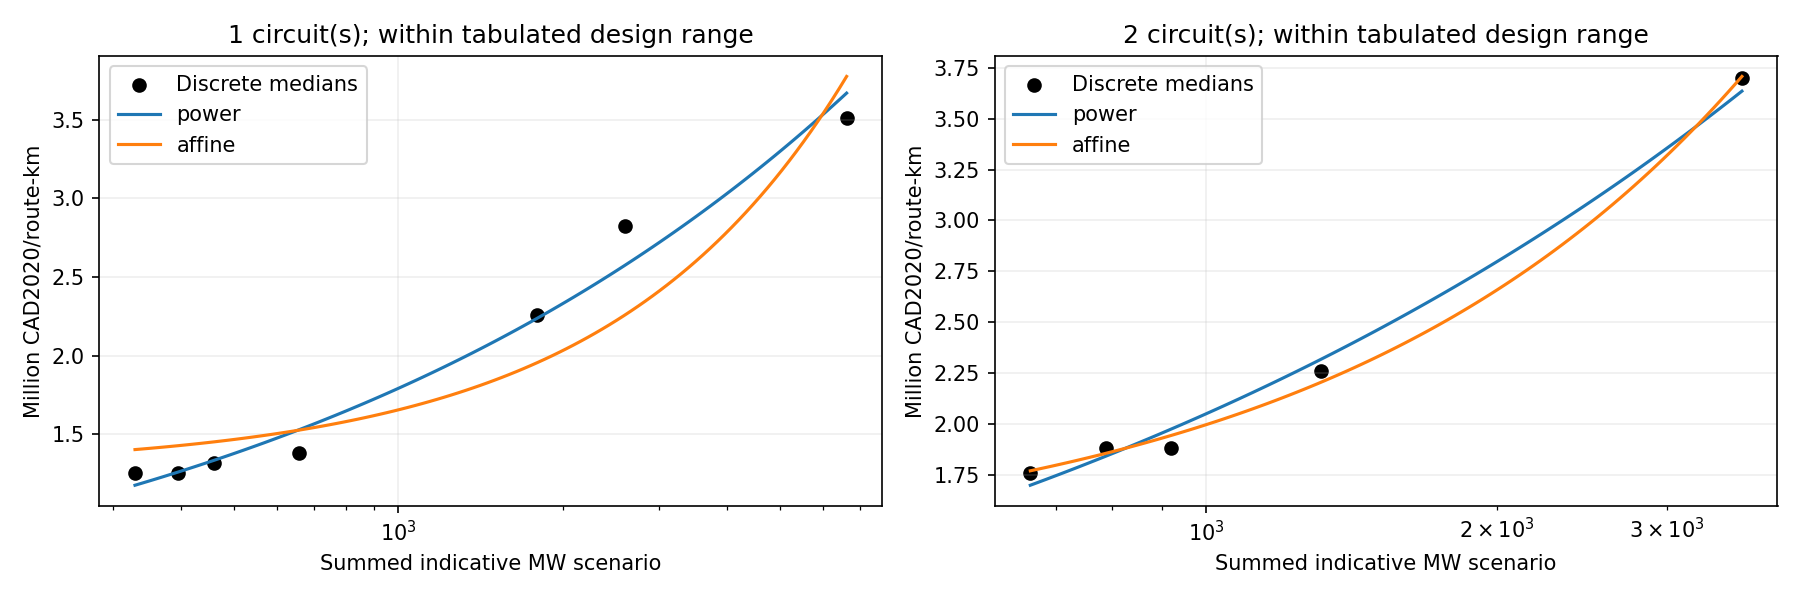

In [6]:
def fit_curve(x, y, form):
    x,y = np.asarray(x,dtype=float),np.asarray(y,dtype=float)
    if len(x)<3 or len(np.unique(x))!=len(x) or np.any(x<=0) or np.any(y<=0):
        raise ValueError('Need at least three unique positive design capacities and costs')
    if form=='power':
        b,loga = np.polyfit(np.log(x),np.log(y),1)
        return float(np.exp(loga)),float(b)
    if form=='affine':
        b,a = np.polyfit(x,y,1)
        return float(a),float(b)
    raise ValueError(form)

def predict_curve(x,a,b,form):
    return a*np.asarray(x)**b if form=='power' else a+b*np.asarray(x)

coefficients, predictions = [],[]
for circuits,g in options.groupby('circuits'):
    x,y = g.capacity_mw_scenario.to_numpy(),g.quoted_median_cad_per_route_km.to_numpy()
    for form in ['power','affine']:
        a,b = fit_curve(x,y,form)
        coefficients.append(dict(circuits=circuits,form=form,a=a,b=b,n_designs=len(g),
            min_capacity_mw=x.min(),max_capacity_mw=x.max(),target_currency=TARGET_CURRENCY,
            cost_scope='quoted line including contingency and AFUDC'))
        for i in range(len(g)):
            xt,yt = np.delete(x,i),np.delete(y,i)
            aa,bb=fit_curve(xt,yt,form)
            predictions.append(dict(circuits=circuits,form=form,held_out_voltage_kv=int(g.iloc[i].voltage_kv),
                actual=y[i],predicted=float(predict_curve(x[i],aa,bb,form)),
                baseline=float(np.median(yt)),extrapolation=bool(x[i]<xt.min() or x[i]>xt.max())))
coefficients=pd.DataFrame(coefficients)
validation=pd.DataFrame(predictions)
validation['absolute_error']=abs(validation.actual-validation.predicted)
validation['absolute_percentage_error']=validation.absolute_error/validation.actual
validation['baseline_absolute_error']=abs(validation.actual-validation.baseline)
validation['nonpositive_prediction']=validation.predicted.le(0)
display(coefficients)
display(validation.groupby(['circuits','form','extrapolation']).agg(
    n_holdouts=('actual','size'),mae=('absolute_error','mean'),
    median_ape=('absolute_percentage_error','median'),baseline_mae=('baseline_absolute_error','mean'),
    invalid_predictions=('nonpositive_prediction','sum')))
# State-specific exponents are a sensitivity to MISO's assumptions, not independent estimates.
state_fit=[]
for (state,circuits),g in data.groupby(['state','circuits']):
    a,b=fit_curve(g.capacity_mw_scenario,g.quoted_cad_per_route_km,'power')
    state_fit.append(dict(state=state,circuits=circuits,a=a,b=b))
state_fit=pd.DataFrame(state_fit)
display(state_fit.groupby('circuits').b.agg(['min','median','max']))
fig,axes=plt.subplots(1,2,figsize=(12,4))
for ax,(circuits,g) in zip(axes,options.groupby('circuits')):
    ax.scatter(g.capacity_mw_scenario,g.quoted_median_cad_per_route_km/1e6,label='Discrete medians',color='black')
    grid=np.geomspace(g.capacity_mw_scenario.min(),g.capacity_mw_scenario.max(),100)
    for _,r in coefficients.loc[coefficients.circuits.eq(circuits)].iterrows():
        ax.plot(grid,predict_curve(grid,r.a,r.b,r.form)/1e6,label=r.form)
    ax.set(xscale='log',xlabel='Summed indicative MW scenario',ylabel=f'Million {TARGET_CURRENCY}/route-km',
           title=f'{circuits} circuit(s); within tabulated design range')
    ax.legend(); ax.grid(alpha=.2)
fig.tight_layout(); fig.savefig(OUT/'curve_comparison.png',dpi=150); plt.show()

## 7. State assumptions, terrain adders and price-year sensitivity

The table's state prices already reflect MISO's indicative land/terrain mix and other
cost assumptions. We display those inputs but do not regress a terrain premium from
15 generated scenarios or add the terrain charges again. A future bottom-up geographic
model would apply component-specific adders to a reconciled component baseline.

The price-year sensitivity **reinterprets the same source quotes** as 2023 or 2024 USD.
It does not apply a second 5% escalation. Currency/GDP rebasing is a common multiplicative
factor, so capacity exponents and relative circuit cost ratios do not change. Financial
conversion does not establish that US engineering costs represent Canadian construction.

In [7]:
display(states)
display(terrain_adders)
price_sensitivity=[]
for year in CONFIG['price_year_sensitivity']:
    scenario_basis=conversion_basis('USD',year)
    for circuits,g in options.groupby('circuits'):
        # Recover native source-unit medians, then apply the alternate interpretation.
        native=g.quoted_median_cad_per_route_km/basis['multiplier']
        values=native*scenario_basis['multiplier']
        a,b=fit_curve(g.capacity_mw_scenario,values,'power')
        price_sensitivity.append(dict(source_year_interpretation=year,circuits=circuits,
            target_currency=scenario_basis['target_currency'],multiplier=scenario_basis['multiplier'],
            median_option_cost_per_km=float(values.median()),power_a=a,power_b=b))
price_sensitivity=pd.DataFrame(price_sensitivity)
display(price_sensitivity)
for circuits,g in price_sensitivity.groupby('circuits'):
    assert np.allclose(g.power_b,g.power_b.iloc[0])

           state  pasture_fraction  ...  source_pdf_page  source_printed_page
0       Arkansas              0.25  ...               35                   34
1       Illinois              0.25  ...               35                   34
2        Indiana              0.25  ...               35                   34
3           Iowa              0.10  ...               35                   34
4       Kentucky              0.25  ...               35                   34
5      Louisiana              0.25  ...               35                   34
6       Michigan              0.25  ...               35                   34
7      Minnesota              0.10  ...               35                   34
8    Mississippi              0.25  ...               35                   34
9       Missouri              0.25  ...               35                   34
10       Montana              0.70  ...               35                   34
11  North Dakota              0.70  ...               35        

## 8. Terminal additions and distance economies

For the selected state/voltage, illustrate the line quote plus **one line position at
each existing terminal for single circuit**, or **two positions at each terminal for
double circuit**, using the selected bus arrangement from Table 4.2-1. Terminal prices
already include contingency/AFUDC; do not add them again. New substations from Table
4.2-2 are shown in the input table but are not implicitly substituted for these upgrades.

This is a specified line-plus-terminal-position scenario, not complete transmission
project CAPEX: transformation, network reinforcements, project-specific compensation
and other unmatched scope remain unmodeled. The 765 kV source ratings also warrant
checking terminal bus limitations before any project scenario there.

Input lengths here are **route lengths**. MISO's 30% straight-line routing adder must
not also be applied to a route length. Summed MW is held constant with length for this
illustration; losses/stability are not modeled. No annual utilization or LCOT is inferred.

       state  voltage_kv  ...  terminal_fraction  target_currency
0  Minnesota         230  ...           0.235401          CAD2020
1  Minnesota         230  ...           0.058003          CAD2020
2  Minnesota         230  ...           0.029868          CAD2020
3  Minnesota         230  ...           0.012165          CAD2020
4  Minnesota         230  ...           0.006120          CAD2020
5  Minnesota         230  ...           0.277694          CAD2020
6  Minnesota         230  ...           0.071401          CAD2020
7  Minnesota         230  ...           0.037022          CAD2020
8  Minnesota         230  ...           0.015145          CAD2020
9  Minnesota         230  ...           0.007630          CAD2020

[10 rows x 11 columns]


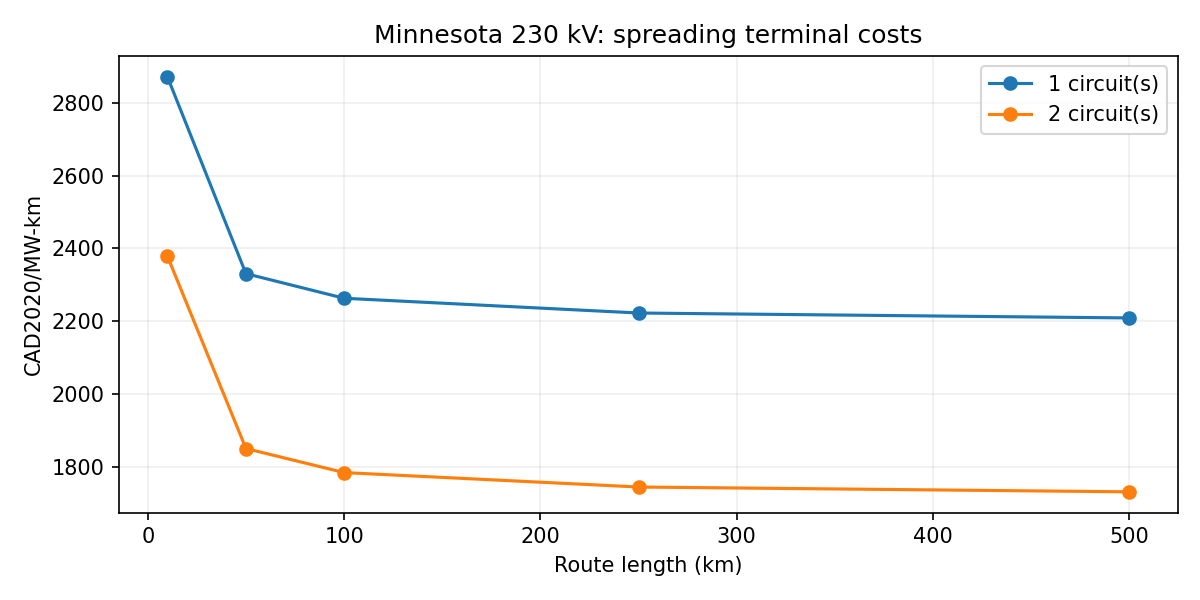

In [8]:
reference=data.loc[data.state.eq(CONFIG['reference_state']) & data.voltage_kv.eq(CONFIG['reference_voltage_kv'])]
assert len(reference)==2, 'Choose a state/voltage with both circuit options for this comparison'
scenario_rows=[]
for _,r in reference.iterrows():
    terminal=stations.loc[stations.scope.eq('upgrade') & stations.positions.eq(r.circuits)
        & stations.bus_arrangement.eq(CONFIG['terminal_bus_arrangement']) & stations.voltage_kv.eq(r.voltage_kv)]
    assert len(terminal)==1
    terminal_pair=2*terminal.iloc[0].cost_usd_per_station*basis['multiplier']
    for length in CONFIG['route_lengths_km']:
        assert np.isfinite(length) and length>0
        line_total=r.quoted_cad_per_route_km*length
        total=line_total+terminal_pair
        scenario_rows.append(dict(state=r.state,voltage_kv=r.voltage_kv,circuits=r.circuits,
            route_km=length,capacity_mw_scenario=r.capacity_mw_scenario,
            line_cost_cad=line_total,terminal_pair_cost_cad=terminal_pair,total_scenario_cost_cad=total,
            scenario_cad_per_mw_km=total/(r.capacity_mw_scenario*length),
            terminal_fraction=terminal_pair/total,target_currency=TARGET_CURRENCY,scope=CONFIG['project_scope']))
project_scenarios=pd.DataFrame(scenario_rows)
display(project_scenarios.drop(columns='scope'))
fig,ax=plt.subplots(figsize=(8,4))
for circuits,g in project_scenarios.groupby('circuits'):
    ax.plot(g.route_km,g.scenario_cad_per_mw_km,'o-',label=f'{int(circuits)} circuit(s)')
ax.set(xlabel='Route length (km)',ylabel=f'{TARGET_CURRENCY}/MW-km',
       title=f"{CONFIG['reference_state']} {CONFIG['reference_voltage_kv']} kV: spreading terminal costs")
ax.legend(); ax.grid(alpha=.2)
fig.tight_layout(); fig.savefig(OUT/'distance_economies.png',dpi=150); plt.show()

## 9. Discrete capacity choices before model integration

For each required nominal MW scenario, find the least-cost feasible **single line
option** among the equal-state median designs, for a chosen route length and selected
terminal arrangement. Oversizing is allowed. Parallel corridors, mixed designs, network
constraints and reliability requirements are not optimized. These are explicit discrete
choices, not a continuous capacity envelope or a national optimum.

Requirements exceeding all tabulated capacities remain infeasible. This exercise helps
decide whether model economies-of-scale segments should reflect actual designs rather
than an unconstrained power-law interpolation. It does not export production ETLSegments.

In [9]:
choice_length_km=100.0  # route-length scenario, not an inferred source-project length
requirements_mw=[250,500,1000,2000,4000,8000]
choice_rows=[]
for required_mw in requirements_mw:
    candidates=[]
    for _,r in options.loc[options.capacity_mw_scenario.ge(required_mw)].iterrows():
        terminals=stations.loc[stations.scope.eq('upgrade') & stations.positions.eq(r.circuits)
            & stations.bus_arrangement.eq(CONFIG['terminal_bus_arrangement']) & stations.voltage_kv.eq(r.voltage_kv)]
        assert len(terminals)==1
        # Bus ratings can constrain high-voltage scenarios; screen against Table 3.2-1.
        bus_mva={69:143,115:398,138:478,161:558,230:797,345:1792,500:2598,765:5300}
        delivered_scenario_mw=min(r.capacity_mva/r.circuits,bus_mva[int(r.voltage_kv)])*r.circuits*CONFIG['power_factor_scenario']
        if delivered_scenario_mw<required_mw:
            continue
        quoted_total=r.quoted_median_cad_per_route_km*choice_length_km+2*terminals.iloc[0].cost_usd_per_station*basis['multiplier']
        candidates.append(dict(required_mw=required_mw,route_km=choice_length_km,voltage_kv=r.voltage_kv,
            circuits=r.circuits,nominal_line_mw=r.capacity_mw_scenario,
            bus_screened_mw=delivered_scenario_mw,total_scenario_cost_cad=quoted_total,feasible=True))
    if candidates:
        choice_rows.append(min(candidates,key=lambda row:row['total_scenario_cost_cad']))
    else:
        choice_rows.append(dict(required_mw=required_mw,route_km=choice_length_km,feasible=False))
choices=pd.DataFrame(choice_rows)
display(choices)
print('Bus screening is indicative only; the simple line model still does not establish network transfer capability.')

   required_mw  route_km  ...  total_scenario_cost_cad  feasible
0          250     100.0  ...             1.284524e+08      True
1          500     100.0  ...             1.424078e+08      True
2         1000     100.0  ...             2.326272e+08      True
3         2000     100.0  ...             2.929034e+08      True
4         4000     100.0  ...             3.863110e+08      True
5         8000     100.0  ...                      NaN     False

[6 rows x 8 columns]
Bus screening is indicative only; the simple line model still does not establish network transfer capability.


## 10. Save review outputs and record interpretation limits

Exports retain source hashes, assumptions and the economic conversion basis. Models
are fitted to quoted costs including contingency/AFUDC; subtotal costs remain separately
labeled. Do not import their coefficients into an overnight-capital-cost model without
reconciling those boundaries. The power-law exponent is range- and design-family-specific.

For Canadian application, compare against AESO after matching scope and dollar basis.
Do not map 230 kV costs or ACSS ratings directly onto an AESO 240 kV ACSR design.
Ontario packages and GSC examples remain contextual benchmarks. Next steps are cost
boundary reconciliation, Canadian calibration, and independently sourced conductor ratings.

In [10]:
tables={'normalized_line_scenarios':data,'discrete_design_options':options,
        'matched_circuit_comparison':matched.reset_index(),
        'curve_coefficients':coefficients,'held_out_design_validation':validation,
        'state_power_law_sensitivity':state_fit,'price_year_sensitivity':price_sensitivity,
        'line_terminal_distance_scenarios':project_scenarios,'discrete_capacity_choices':choices}
for name,table in tables.items():
    table.to_csv(OUT/(name+'.csv'),index=False)
manifest={'source_pdf_sha256':PROVENANCE['pdf_sha256'],
          'source_tables_sha256':PROVENANCE['files'],
          'assumptions_sha256':sha256(INPUTS/'analysis_assumptions.json'),
          'source_provenance_sha256':sha256(INPUTS/'source_provenance.json'),
          'config':CONFIG,'economic_basis':basis,
          'counts':{'source_line_scenarios':len(lines),'selected_line_scenarios':len(data),
                    'unique_design_options':len(options),'independent_project_observations':0},
          'outputs':{name+'.csv':sha256(OUT/(name+'.csv')) for name in tables},
          'production_ready':False}
(OUT/'review_manifest.json').write_text(json.dumps(manifest,indent=2),encoding='utf8')
print('Saved review outputs:',OUT)
print('Power-law exponents by circuit family:')
display(coefficients.loc[coefficients.form.eq('power'),['circuits','b','n_designs','min_capacity_mw','max_capacity_mw']])

Saved review outputs: C:\Users\Andrew Vigars\Research\repos\temoa-upstream\temoa_geospace\data_files\processed\transmission\miso\notebook24
Power-law exponents by circuit family:
   circuits         b  n_designs  min_capacity_mw  max_capacity_mw
0         1  0.378528          7            329.0           6625.0
2         2  0.449358          5            658.0           3584.0
